Partie 1 : Introduction au Dataset 

In [67]:
import pandas as pd
import numpy as np
df=pd.read_csv(r"C:\Users\dell\Desktop\Titanic.csv")
print(df.dtypes)

sex          object
age         float64
sibsp         int64
parch         int64
fare        float64
embarked     object
class        object
who          object
alone          bool
survived      int64
dtype: object


In [68]:
print(df.head())

      sex   age  sibsp  parch     fare embarked  class    who  alone  survived
0    male  22.0      1      0   7.2500        S  Third    man  False         0
1  female  38.0      1      0  71.2833        C  First  woman  False         1
2  female  26.0      0      0   7.9250        S  Third  woman   True         1
3  female  35.0      1      0  53.1000        S  First  woman  False         1
4    male  35.0      0      0   8.0500        S  Third    man   True         0


In [69]:
print(df.isnull().sum())

sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
class         0
who           0
alone         0
survived      0
dtype: int64


Partie 2 : Nettoyage des Données

In [70]:
print(df.isna().mean)

<bound method DataFrame.mean of        sex    age  sibsp  parch   fare  embarked  class    who  alone  \
0    False  False  False  False  False     False  False  False  False   
1    False  False  False  False  False     False  False  False  False   
2    False  False  False  False  False     False  False  False  False   
3    False  False  False  False  False     False  False  False  False   
4    False  False  False  False  False     False  False  False  False   
..     ...    ...    ...    ...    ...       ...    ...    ...    ...   
886  False  False  False  False  False     False  False  False  False   
887  False  False  False  False  False     False  False  False  False   
888  False   True  False  False  False     False  False  False  False   
889  False  False  False  False  False     False  False  False  False   
890  False  False  False  False  False     False  False  False  False   

     survived  
0       False  
1       False  
2       False  
3       False  
4       Fal

In [71]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
x=df.drop("survived",axis=1)
y=df["survived"]

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,stratify=y,random_state=42)
num_cols=["age","sibsp","parch","fare"]
cat_cols=["sex","embarked","class","who","alone"]

num_imputer=SimpleImputer(strategy="median")
x_train[num_cols]=num_imputer.fit_transform(x_train[num_cols])
x_test[num_cols]=num_imputer.transform(x_test[num_cols])

cat_imputer=SimpleImputer(strategy="most_frequent")
x_train[cat_cols]=cat_imputer.fit_transform(x_train[cat_cols])
x_test[cat_cols]=cat_imputer.transform(x_test[cat_cols])


In [72]:
seuil=0.40
col_supp=df.columns[df.isna().mean()>0.40]
if len(col_supp)>0:
  df=df.drop(columns=col_supp)
print(df.shape[1])

10


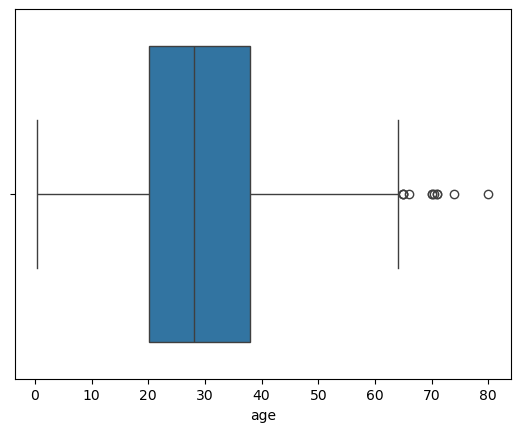

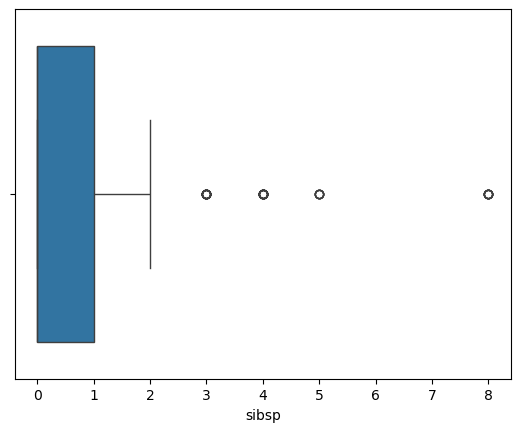

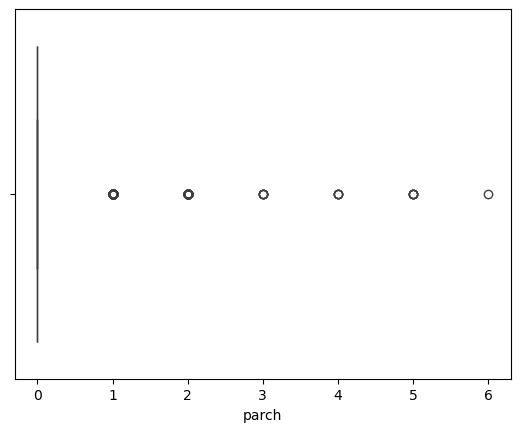

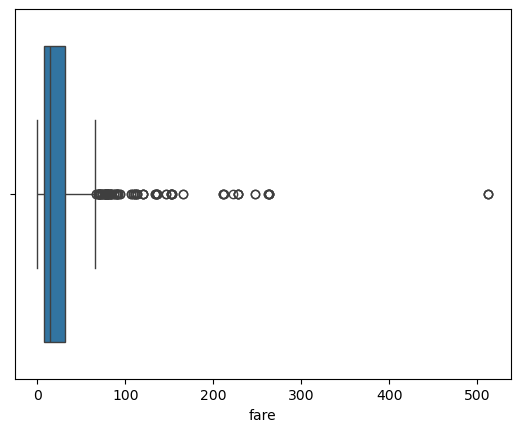

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ["age","sibsp","parch","fare" ]

for col in num_cols:
    sns.boxplot(x=df[col])
    plt.show()

In [74]:
q1=x_train["fare"].quantile(0.25)
q3=x_train["fare"].quantile(0.75)
IQR=q3-q1
L=q1-1.5*IQR
U=q3+1.5*IQR

med_remp=x_train["fare"].median()
x_train["fare"]=x_train["fare"].apply(lambda x:med_remp if x<L or x>U else x)
print("median est",med_remp)
print("L=",L)
print("U=",U)


median est 14.4542
L= -26.7605
U= 65.6563


Partie 3 : Transformation des Données

In [75]:
cat_cols=["sex","embarked","class","who","alone"]
print( "les variables categorie est:",cat_cols)

les variables categorie est: ['sex', 'embarked', 'class', 'who', 'alone']


In [76]:
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
nom_col=["sex","embarked","who"]
nom_pipeline=Pipeline([
('imputer',SimpleImputer(strategy='most_frequent')),
('onehot',OneHotEncoder(handle_unknown="ignore",sparse_output=False))
])

ordr_cols=["class"]
ordr_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
     ("ordinal",OrdinalEncoder(categories=[["Third","Second","First"]]))])
     
num_cols = ["age","sibsp","parch","fare" ]
num_pepline=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
     ("scaler",MinMaxScaler())
 ])

prep=ColumnTransformer(
    transformers=[
        ("nominal",nom_pipeline,nom_col),
        ("ordinal",ordr_pipeline,ordr_cols),
        ("numeric", num_pepline,num_cols)
    ]
)


    

In [78]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
num_cols = ["age","sibsp","parch","fare" ]
norm_pipline=make_pipeline(MinMaxScaler())
x_train_norm=norm_pipline.fit_transform(x_train[num_cols])
x_test_norm=norm_pipline.transform(x_test[num_cols])


In [79]:
from sklearn.preprocessing import StandardScaler
stand_pipline=make_pipeline(StandardScaler())
x_train_stad=stand_pipline.fit_transform(x_train[num_cols])
x_test_stad=stand_pipline.transform(x_test[num_cols])

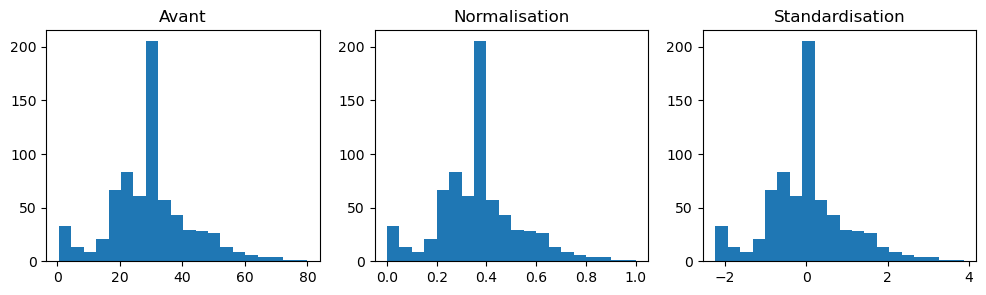

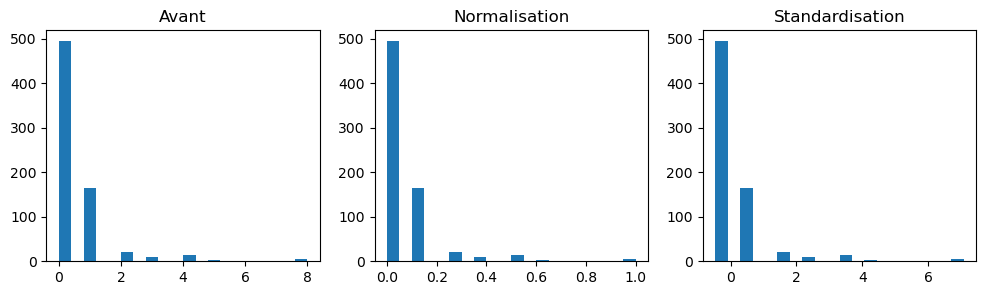

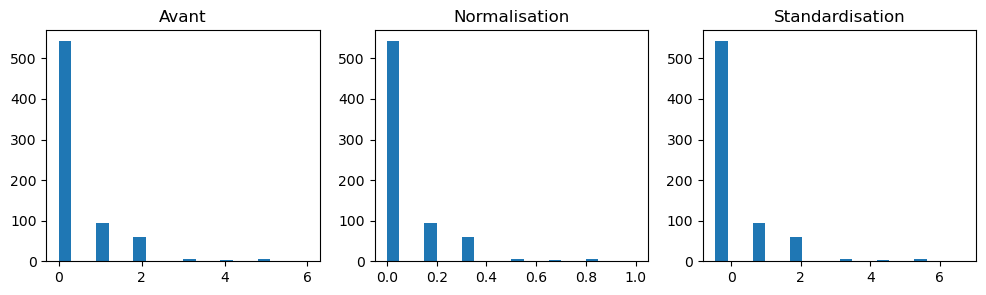

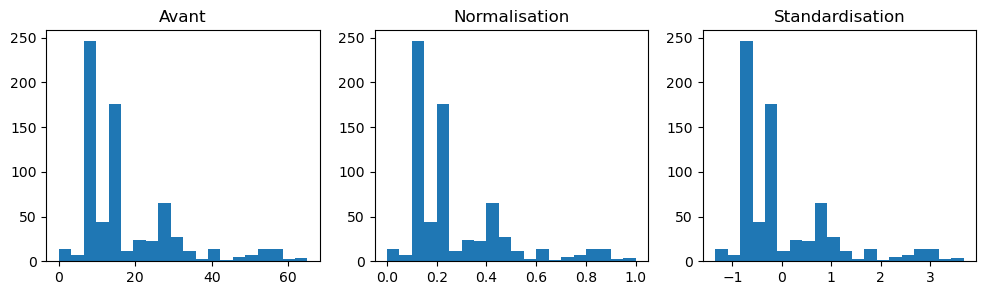

In [85]:
import matplotlib.pyplot as plt
import pandas as pd

df_norme = pd.DataFrame(x_train_norm, columns=num_cols)
df_stdan= pd.DataFrame(x_train_stad, columns=num_cols)

for col in num_cols:
    plt.figure(figsize=(12, 3))

    plt.subplot(1, 3, 1)
    plt.hist(x_train[col].dropna(), bins=20)
    plt.title("Avant")

    plt.subplot(1, 3, 2)
    plt.hist(df_norme[col], bins=20)
    plt.title("Normalisation")

    plt.subplot(1, 3, 3)
    plt.hist(df_stdan[col], bins=20)
    plt.title("Standardisation")

    plt.show()

Partie 4 : Gestion des Données Déséquilibrées

In [ ]:
surv=y_train.value_counts()
print (surv)

In [ ]:
from imblearn.under_sampling  import RandomUnderSampler
print(y_train.value_counts())
x=df.drop("survived",axis=1)
y=df["survived"]
rus = RandomUnderSampler(random_state=42)
x_train, y_train = rus.fit_resample(x, y)


In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import OneHotEncoder
onehot=OneHotEncoder(handle_unknown="ignore")
x_train_encoded =onehot.fit_transform(x_train[cat_cols])
x_test_encoded = onehot.transform(x_test[cat_cols])

smote=SMOTE(random_state=42)
x_train_smote,y_train_smote=smote.fit_resample(x_train_encoded,y_train)
print(y_train_smote.value_counts())
